# Simulate radar in a conductive soil (Maxwell TM with losses)

Maxwell's TM equations with a conductivity `sigma`: the term `-sigma / eps * Ey` in the `Ey` equation, a field times a coefficient in its own equation, which the DSL steps with the trapezoidal rule. The same 400 MHz pulse and buried pipe as the lossless radar notebook run as one batch of two shots: dry sand (sigma = 0) on the left, a moist soil (sigma = 10 mS/m) on the right, drawn on one colour scale. The pulse fades with distance and the echo from the pipe nearly vanishes.

In [1]:
import numpy as np
import sympy
import torch
from IPython.display import Image

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Coefficient, Eq, Field, Model, laplace

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.allow_tf32 = False                 # full fp32 stencils
opts = EagerOptions(use_compile=False)

Helpers: a Ricker wavelet, a run that keeps snapshots, and a GIF writer.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def ricker(nt, dt, f0):
    a = (np.pi * f0 * (np.arange(nt) * dt - 1.5 / f0)) ** 2
    return torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)


def snapshots(solver, wavelet, sources, receivers, models, every=10, **kwargs):
    """Run one batch; return the record, every field every `every` steps (cropped to the model) and the times."""
    steps = list(range(every - 1, solver.nt, every))
    with torch.no_grad():
        record, snap = solver(wavelet, sources, receivers, models=models, return_wavefield=True,
                              snapshot_times=steps, **kwargs)
    nz, nx = models[0].shape[-2:]
    x0, _, z0, _ = solver._runtime_padding()
    if snap.shape[-2] - nz < z0 or snap.shape[-1] - nx < x0:   # padding not as reported: centre the crop
        z0, x0 = (snap.shape[-2] - nz) // 2, (snap.shape[-1] - nx) // 2
    snap = snap[..., z0:z0 + nz, x0:x0 + nx]
    names = [f.name for f in solver.equation.field_specs]
    frames = {n: snap[:, i, :, 0].numpy() for i, n in enumerate(names) if not n.startswith("_")}
    return record.cpu(), frames, (np.array(steps) + 1) * float(solver.dt)


def save_gif(path, panels, times, extent, xlabel="x (km)", ylabel="z (km)", unit="s", cmap="seismic",
             clip=99.8, outline=None, normalize=False, share=False):
    """Animate panels [(title, frames (nframe, nz, nx))] with fixed colour limits; outline: a model drawn as contours;
    share: one colour scale for every panel."""
    aspect = abs(extent[1] - extent[0]) / abs(extent[2] - extent[3])
    fig, axes = plt.subplots(1, len(panels), figsize=((3.2 * aspect + 0.45) * len(panels), 3.6),
                             squeeze=False, constrained_layout=True)
    outlines = outline if isinstance(outline, list) else [outline] * len(panels)
    images = []
    for k, (ax, (title, data), line) in enumerate(zip(axes[0], panels, outlines)):
        if normalize:
            data = data / np.abs(data).max(axis=(1, 2), keepdims=True).clip(min=1e-30)
        if cmap == "seismic":
            a = np.percentile(np.abs(np.stack([d for _, d in panels]) if share else data), clip) or 1.0
            lo, hi = -a, a
        else:
            lo, hi = np.percentile(data, [100 - clip, clip])
        im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, extent=extent, interpolation="bilinear")
        if line is not None:
            ax.contour(line, levels=6, colors="k", linewidths=0.5, alpha=0.35, extent=extent, origin="upper")
        ax.set(title=title, xlabel=xlabel)
        if k == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        images.append((im, data))
    clock = fig.suptitle("")

    def draw(i):
        for im, data in images:
            im.set_data(data[i])
        clock.set_text(f"t = {times[i]:.3g} {unit}")

    FuncAnimation(fig, draw, frames=len(times)).save(path, writer=PillowWriter(fps=10), dpi=70)
    plt.close(fig)
    return path

## The PDE

Declare the models and fields, write one equation per field, and build the equation class.

In [3]:
EPS0, MU0 = 8.8541878128e-12, 1.25663706212e-6
eps_r, sigma = Model("eps_r"), Model("sigma")
inv_eps = Coefficient("inv_eps", 1 / (EPS0 * eps_r))
loss = Coefficient("loss", sigma / (EPS0 * eps_r))

ey = Field("Ey", time_order=1, source=True, receiver=True)
hx = Field("Hx", time_order=1, stagger="z", receiver=True)
hz = Field("Hz", time_order=1, stagger="x", receiver=True)

pde = PDE([Eq(hx.dt, ey.dz / MU0),
           Eq(hz.dt, -ey.dx / MU0),
           Eq(ey.dt, inv_eps * (hx.dz - hz.dx) - loss * ey)], name="LossyMaxwellTM")
LossyMaxwellTM = pde.build(ndim=2)
pde

PDE([Eq(Hx.dt, 795774.715026276*Ey.dz), Eq(Hz.dt, -795774.715026276*Ey.dx), Eq(Ey.dt, inv_eps*(Hx.dz - Hz.dx) - loss*Ey)], name='LossyMaxwellTM')

## Run it

A model, a propagator, one batch of shots; a snapshot of every field is kept at regular steps.

In [4]:
nz, nx, h, f0 = 200, 300, 0.01, 4e8                          # 1 cm cells, 400 MHz
z, x = np.mgrid[0:nz, 0:nx]
er = np.full((nz, nx), 4.0)
er[(z - 80) ** 2 + (x - 190) ** 2 <= 10**2] = 30.0           # a water-filled pipe
cmax = 1 / np.sqrt(EPS0 * MU0 * er.min())
dt = 0.35 * h / cmax
nt = 900
er_b = torch.tensor(np.stack([er, er]), dtype=torch.float32, device=dev)
sigma_b = torch.stack([torch.zeros(nz, nx), torch.full((nz, nx), 0.01)]).to(dev)

solver = PropTorch(LossyMaxwellTM(8, device=dev), shape=(nz, nx), dh=h, dt=dt, nt=nt, dev=dev,
                   impl="eager", memory=Full(), source_type=["Ey"], receiver_type=["Ey"], eager_options=opts)
src = np.array([[100, 10]] * 2)
rec = np.array([[[ix, 10] for ix in range(nx)]] * 2)
record, frames, t = snapshots(solver, ricker(nt, dt, f0), src, rec, [er_b, sigma_b], every=18,
                              max_vel=cmax, pml_freq=f0)

## The wavefield

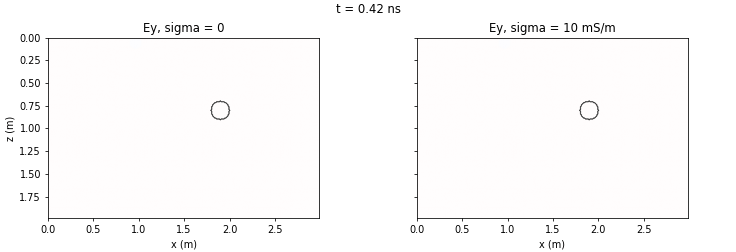

In [5]:
ext = [0, (nx - 1) * h, (nz - 1) * h, 0]
gif = save_gif("82_symbolic_lossy_gpr.gif", [("Ey, sigma = 0", frames["Ey"][:, 0]),
                                             ("Ey, sigma = 10 mS/m", frames["Ey"][:, 1])],
               t * 1e9, ext, xlabel="x (m)", ylabel="z (m)", unit="ns", outline=er, share=True)
Image(filename=gif)